# Phase 1: Multi-prototype study

## Section 1 - Purpose and overview

This study asks whether representing a class with more than one prototype corrects the known limits of perception: the empty mouth slot predicted as mouth, the loose mouth seen from the side, and the identity of the two arms, without making the rest worse.

The current method represents each class with one prototype, the normalized mean of its annotated patches (Snell et al. 2017, Sect. 2.2). A diagnostic on the reference frames showed why a mean can fail. The empty mouth slot is annotated, inside the body polygon of 3_disassembled_ordered_f0001, but it is one patch out of 251 body patches, and that patch is closer to the mouth prototype than to the body prototype. An example can be present and still be lost in the mean.

Two changes are made, in this order: first the examples, then how they are used.

The examples follow a coverage rule: for each piece, the support set contains at least one example of each state in which the piece appears during the assembly. This is our own design rule. It is in the spirit of the viewpoint annotation of PASCAL VOC, introduced for methods that treat different viewpoints separately (Everingham et al. 2010, Sect. 3.3). Two states are missing from the current support set, and one frame is added for each, from reference recordings only. caos_f0043 adds the loose mouth seen from the side (use_labels: mouth). 4_partially_assembled_f0002 adds the body on the base with the face not yet complete, including the empty mouth slot, and a loose mouth seen at three quarters (use_labels: body, mouth). All visible pieces are annotated in both frames, so that unused pieces become ignored patches and not background. 4_partially_assembled_f0002 was a candidate in the support-set study and was not selected there; it enters now because of the coverage rule, not because of a score. The support set of 10 frames is adopted by rule, and its comparison with the support set of 8 frames is reported only as a description.

How the examples are used is the question of the study. Mensink et al. (2013, Sect. 1) contrast two distance-based classifiers: the nearest class mean, which represents a class by its mean, and the k-nearest neighbour, which uses all its examples. They also extend the first to several centroids per class (Sect. 3.3). Three variants follow from this. V0 is the current method, one prototype per class. V1 has one prototype per class and aspect, mounted or loose, and background and hand keep a single prototype. The aspect of each piece in each reference frame is declared as an annotated attribute, as the viewpoint in PASCAL VOC (Everingham et al. 2010, Sect. 3.3), rather than computed: a geometric rule would need a distance to the figure, and the labelled patches of a mounted arm, mostly the hand, lie several patches away from the body. This is the idea of several centroids per class, with the groups given by the aspect rather than by k-means, because the slot and the side view of the mouth cover one to three patches and could not form a cluster of their own. On unit vectors it corresponds to a mixture of von Mises-Fisher distributions (Banerjee et al. 2005, Sect. 3). V2 uses every annotated patch as a prototype, the nearest neighbour. In all variants the similarity of a class is the highest similarity among its prototypes, and the background margin is applied as before.

The hypotheses are written before running. In V0 the two new frames change little, because their few patches are lost in the means, as in the support-set study. V2 should predict the empty slot as body, because the annotated slot patches become body prototypes; the risk is that body patches next to the face, which already look like face pieces, take patches from the face pieces. V1 probably does not correct the slot, which stays a few patches in the mean of its aspect. The side view of the mouth keeps one patch after labelling, so only V2 can use it. No variant should correct the identity of the arms along their stick, where the patches of the two arms look the same. Mensink et al. found the nearest class mean better than the nearest neighbour in their setting, so V2 may also be worse overall.

The decision rule is the one of the support-set study. A variant replaces V0 only if the paired 95% bootstrap interval of the mIoU difference, with the arms merged and background margin 0.03, lies entirely above zero (Koehn 2004, Sect. 6). If both variants pass, V1 is chosen, being simpler and faster, unless V2 is better than V1 by the same criterion. Three targeted measures are reported but do not enter the rule: body patches predicted as mouth in the frames where the mouth is not mounted, the share of arm patches given the right arm, loose and mounted, and the mouth IoU in the two validation frames of 1_disassembled_controlled_caos. The time of classification is also measured, since V2 compares each patch with tens of thousands of prototypes.

The two new frames were motivated by errors seen on validation, and the variants are chosen on validation, which makes the results optimistic (Cawley and Talbot 2010, Sect. 4.4 and 5). For this reason the variants are few and fixed here, and the test sequence (assembly_1) is not read.

Section 2 sets the configuration. Section 3 checks that the new code reproduces the current results. Section 4 builds the variants, Section 5 compares them, Section 6 reports the targeted measures, Section 7 the time, and Section 8 applies the rule.

------------------------------------------------------------------------------------------------------------------------------------------

References Section 1:

Snell et al. 2017, Sect. 2.2: the prototype of a class is the mean vector of its embedded support points.

Mensink et al. 2013, Sect. 1: the k-nearest neighbour classifier uses all examples to represent a class, the nearest class mean classifier uses their mean; in their experiments the nearest class mean outperforms k-NN. Sect. 3.3: nearest class multiple centroids (NCMC), several centroids per class obtained with k-means.

Banerjee et al. 2005, Sect. 3: mixture of von Mises-Fisher distributions, a generative model with several mean directions for unit vectors.

Everingham et al. 2010, PASCAL VOC, Sect. 3.3: objects are annotated with a viewpoint (front, rear, left, right, unspecified), to support methods that treat different viewpoints differently, such as separate detectors for each viewpoint.

Koehn 2004, Sect. 6: paired bootstrap resampling.

Cawley and Talbot 2010, Sect. 4.4: selection by optimizing a criterion on a finite sample over-fits, more so with small samples and many choices. Sect. 5: performance estimated on the data used for selection is optimistically biased.

------------------------------------------------------------------------------------------------------------------------------------------

## Section 2 - Configuration

All paths, frames and hyperparameters in one place. The values are those of the pipeline (Section 2.5) and of the support-set study (Section 2.4). The support set has two more frames, added by the coverage rule (Section 1).

In [1]:
# 2.1 Dependencies: install once per environment with pip install -r requirements.txt (README, Setup)

In [2]:
# 2.2 Imports
%load_ext autoreload
%autoreload 2

import sys
import json
import time
import hashlib
import platform
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from PIL import Image
from scipy import ndimage
import transformers
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import cv2

In [3]:
# 2.3 Paths and shared module
PROJECT_ROOT = Path.cwd().parent
SRC_DIR = PROJECT_ROOT / "src"
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))   # makes src/perception importable from notebooks/

MODEL_DIR = PROJECT_ROOT / "models" / "c_radio_weights"
FRAMES_DIR = PROJECT_ROOT / "data" / "extracted_frames"
OUTPUT_DIR = PROJECT_ROOT / "outputs" / "phase_1_multi_prototype_study"
PIPELINE_DIR = PROJECT_ROOT / "outputs" / "phase_1_perception"
PIPELINE_PROTOTYPES_PATH = PIPELINE_DIR / "prototypes.npz"                    # saved by the pipeline (v1.3): 8 reference frames
PIPELINE_SIMILARITIES_PATH = PIPELINE_DIR / "validation_similarities.npz"     # saved by the pipeline (v1.3): 8 validation frames

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

for name, path in {"MODEL_DIR": MODEL_DIR, "FRAMES_DIR": FRAMES_DIR, "SRC_DIR": SRC_DIR,
                   "PIPELINE_PROTOTYPES_PATH": PIPELINE_PROTOTYPES_PATH,
                   "PIPELINE_SIMILARITIES_PATH": PIPELINE_SIMILARITIES_PATH}.items():
    status = "OK" if path.exists() else "MISSING"
    print(f"[{status}] {name}: {path}")

# Shared code (src/perception)
from perception.classes import (CLASS_NAMES, BACKGROUND_ID, HAND_LABEL, PIECE_LABELS, IGNORE_ID,
                                CLASS_COLORS, PATCH_LABEL_NAMES)
from perception.features import FeatureExtractor
from perception.labels import sequence_of, check_annotation, rasterize_annotation, patch_label_grid
from perception.prototypes import (build_prototypes, stack_prototypes, load_prototypes, classify_patches,
                                   assign_labels, group_prototypes, patch_prototypes, class_similarities, class_similarities_gpu, sort_by_class)
from perception.metrics import (confusion_matrix, iou_from_confusions, mean_iou, ignore_boundary_ring,
                                MERGED_NAMES, MERGED_PIECES, merge_arms, merged_ids,
                                frame_iou, frame_miou, bootstrap_miou, bootstrap_class_iou, percentile_interval)
from perception.visualization import label_grid_to_rgb

[OK] MODEL_DIR: c:\Users\ADV\Universita\Magistrale\Tesi\vad-project\models\c_radio_weights
[OK] FRAMES_DIR: c:\Users\ADV\Universita\Magistrale\Tesi\vad-project\data\extracted_frames
[OK] SRC_DIR: c:\Users\ADV\Universita\Magistrale\Tesi\vad-project\src
[OK] PIPELINE_PROTOTYPES_PATH: c:\Users\ADV\Universita\Magistrale\Tesi\vad-project\outputs\phase_1_perception\prototypes.npz
[OK] PIPELINE_SIMILARITIES_PATH: c:\Users\ADV\Universita\Magistrale\Tesi\vad-project\outputs\phase_1_perception\validation_similarities.npz


In [4]:
# 2.4 Hyperparameters
# Same values as the pipeline (Section 2.5) and the support-set study (Section 2.4).

# --- Feature extraction ---
DEVICE = "cuda"
DTYPE = torch.bfloat16          # input resolution: native 1024x1024 (resolution study)

# --- Patch labelling ---
MIN_LABEL_COVERAGE = 0.5        # same rule as the pipeline (Section 5)

# --- Classification ---
CONFIDENCE_MARGIN = 0.03        # background margin, provisional (pipeline, Section 9): not tuned here
EVAL_MARGINS = [0.0, CONFIDENCE_MARGIN]
PROTOTYPE_CHUNK = 4096          # prototypes compared at once in class_similarities: memory only, results unchanged

# --- Evaluation ---
N_BOOTSTRAP = 1000              # resamples of the validation frames (support-set study, Section 5.4)
BOUNDARY_RING = 1               # secondary metric: background patches within 1 patch of an object are ignored

# --- Latency (Section 7), same protocol as the pipeline, Section 12 ---
N_WARMUP, N_RUNS = 5, 50

# --- Reproducibility ---
RANDOM_SEED = 0
np.random.seed(RANDOM_SEED)
_ = torch.manual_seed(RANDOM_SEED)

In [5]:
# 2.5 Frames and split
# Validation: errors are inspected and the variants are chosen here.
# Test: held out until the end of all studies. This notebook never reads a test frame.
VALIDATION_SEQUENCES = {"assembly_2", "1_disassembled_controlled_caos"}
TEST_SEQUENCES = {"assembly_1"}
assert not VALIDATION_SEQUENCES & TEST_SEQUENCES


def frame_path(frame, suffix=".jpg"):
    """Path of a frame or of its annotation. Refuses test frames, so the test set cannot be read by mistake."""
    assert sequence_of(frame) not in TEST_SEQUENCES, f"{frame} belongs to the held-out test set"
    return FRAMES_DIR / f"{frame}{suffix}"


# Current support set (support-set study, Section 6.5), in the order of the pipeline (Section 4.1)
CURRENT_REFERENCE_FRAMES = [
    {"frame": "5_assembled_f0002",            "role": "assembled",                   "use_labels": PIECE_LABELS},
    {"frame": "caos_f0149",                   "role": "partially assembled",         "use_labels": PIECE_LABELS},
    {"frame": "5_assembled_f0019",            "role": "assembled, 3/4 view",         "use_labels": PIECE_LABELS},
    {"frame": "3_disassembled_ordered_f0001", "role": "disassembled",                "use_labels": PIECE_LABELS - {"base"}},
    {"frame": "2_disassembled_caos_f0016",    "role": "disassembled, top-down view", "use_labels": PIECE_LABELS - {"base"}},
    {"frame": "Take_3_1_Base_f0099",          "role": "base only, upright",          "use_labels": {"base"}},
    {"frame": "Take_3_1_Base_f0131",          "role": "base only, lying",            "use_labels": {"base"}},
    {"frame": "caos_f0211",                   "role": "hands",                       "use_labels": {HAND_LABEL}},
]

# Frames added by the coverage rule (Section 1): one per missing state
COVERAGE_FRAMES = [
    {"frame": "4_partially_assembled_f0002",  "role": "body on base, face incomplete (empty mouth slot); mouth loose at 3/4",
     "use_labels": {"body", "mouth"}},
    {"frame": "caos_f0043",                   "role": "mouth loose, side view", "use_labels": {"mouth"}},
]
REFERENCE_FRAMES = CURRENT_REFERENCE_FRAMES + COVERAGE_FRAMES

# Validation frames in the order of the support-set study (Section 2.5): bootstrap resamples pick frames by position
VALIDATION_FRAMES = [
    {"frame": "assembly_2_f0003", "stage": "all pieces loose"},
    {"frame": "assembly_2_f0017", "stage": "body on base"},
    {"frame": "assembly_2_f0030", "stage": "hands: piece held in hand"},
    {"frame": "assembly_2_f0046", "stage": "face (eyes, nose, moustache, mouth)"},
    {"frame": "assembly_2_f0057", "stage": "ears mounted"},
    {"frame": "assembly_2_f0068", "stage": "arms mounted"},
    {"frame": "1_disassembled_controlled_caos_f0001", "stage": "disassembled, front view", "exclude": {"base"}},
    {"frame": "1_disassembled_controlled_caos_f0016", "stage": "disassembled, side view",  "exclude": {"base"}},
]

# No leakage: reference frames never come from validation or test sequences
for ref in REFERENCE_FRAMES:
    assert sequence_of(ref["frame"]) not in VALIDATION_SEQUENCES | TEST_SEQUENCES, f"Leakage: {ref['frame']}"
    ref["image_path"], ref["json_path"] = frame_path(ref["frame"]), frame_path(ref["frame"], ".json")
for val in VALIDATION_FRAMES:
    assert sequence_of(val["frame"]) in VALIDATION_SEQUENCES, f"{val['frame']} is not a validation frame"
    assert frame_path(val["frame"]).exists(), f"Missing frame: {val['frame']}"

GT_LABELS = PIECE_LABELS | {HAND_LABEL}   # ground truth: every official class; legacy labels become ignored patches

print(f"{len(REFERENCE_FRAMES)} reference frames ({len(CURRENT_REFERENCE_FRAMES)} current + "
      f"{len(COVERAGE_FRAMES)} added by coverage), {len(VALIDATION_FRAMES)} validation frames")

10 reference frames (8 current + 2 added by coverage), 8 validation frames


In [6]:
# 2.5b Aspect of the pieces in each reference frame: an annotated attribute, as the viewpoint in PASCAL VOC
# (Everingham et al. 2010, Sect. 3.3). Mounted means: body on the base, base under the body, any other piece
# inserted in the body.
# "mounted": every piece is mounted; "loose": every piece is loose;
# "mixed": the mounted pieces are the polygons with group_id 1 in the labelme file;
# None: a single aspect (frames with hands only).
FRAME_ASPECT = {
    "5_assembled_f0002": "mounted",
    "caos_f0149": "mixed",
    "5_assembled_f0019": "mounted",
    "3_disassembled_ordered_f0001": "loose",
    "2_disassembled_caos_f0016": "loose",
    "Take_3_1_Base_f0099": "loose",          # base alone counts as not mounted
    "Take_3_1_Base_f0131": "loose",
    "caos_f0211": None,
    "4_partially_assembled_f0002": "mixed",
    "caos_f0043": "loose",
}
assert set(FRAME_ASPECT) == {ref["frame"] for ref in REFERENCE_FRAMES}, "Every reference frame needs an aspect"

In [7]:
# 2.6 Annotation fingerprints: data/ is not tracked by git, so the notebook records which annotations it used
def fingerprint(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()[:12]

display(pd.DataFrame({
    "set": ["reference"] * len(REFERENCE_FRAMES) + ["validation"] * len(VALIDATION_FRAMES),
    "annotation sha256": [fingerprint(ref["json_path"]) for ref in REFERENCE_FRAMES]
                         + [fingerprint(frame_path(val["frame"], ".json")) for val in VALIDATION_FRAMES],
}, index=[ref["frame"] for ref in REFERENCE_FRAMES] + [val["frame"] for val in VALIDATION_FRAMES]))

,set,annotation sha256
5_assembled_f0002,reference,e85d1c179582
caos_f0149,reference,14f88d7cf080
5_assembled_f0019,reference,1cd8cdcc2c9b
3_disassembled_ordered_f0001,reference,319c3601f0a1
2_disassembled_caos_f0016,reference,f17ab6af8218
Take_3_1_Base_f0099,reference,853e60024c17
Take_3_1_Base_f0131,reference,f07f67aae3a9
caos_f0211,reference,3c56b4804e54
4_partially_assembled_f0002,reference,32a94339f2b4
caos_f0043,reference,3b555dd93c2c


Observation 2.6: After the first execution of this notebook, the fingerprints of several annotation files changed: the two mixed reference frames, where the mounted polygons were marked (Section 4), and other files that were opened and saved again in labelme without changing their polygons or labels. The regression check (Section 3) and the unchanged results confirm that the patch labels of the reference and validation frames are the same.

In [8]:
# 2.7 Environment
print(f"Python       : {platform.python_version()}")
print(f"PyTorch      : {torch.__version__}")
print(f"Transformers : {transformers.__version__}")
print(f"CUDA         : {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU          : {torch.cuda.get_device_name(0)}")

Python       : 3.10.0
PyTorch      : 2.5.1+cu121
Transformers : 5.17.0
CUDA         : True
GPU          : NVIDIA GeForce RTX 4060 Laptop GPU


------------------------------------------------------------------------------------------------------------------------------------------

References Section 2: none. The values are taken from the pipeline (Section 2.5) and the support-set study (Section 2.4); the two added frames follow the coverage rule of Section 1.

------------------------------------------------------------------------------------------------------------------------------------------

## Section 3 - Regression check

The prototypes can now be built and compared with new shared functions (group_prototypes, patch_prototypes, class_similarities). Before using them for the variants, this section checks that in the simplest case, one prototype per class from the current 8 reference frames, they reproduce the pipeline exactly. Otherwise a difference between the variants could come from the code and not from the method.

Four things are checked. The prototypes are bitwise identical to those saved by the pipeline (v1.3). group_prototypes, with a single group per class, gives the same prototypes as build_prototypes. class_similarities, with one prototype per class, gives the validation similarities saved by the pipeline, bitwise. The mIoU of the current method is the one reported by the support-set study. Exact comparisons are possible because feature extraction is deterministic on this machine (support-set study, Section 3.2), although this is not guaranteed across releases or platforms (PyTorch documentation, Reproducibility).

This section also extracts the features of all 10 reference frames and of the validation frames, and prepares the ground truth, as in the support-set study (Section 4.2).

In [9]:
# 3.1 Loading the model (shared FeatureExtractor, same settings as the pipeline)
extractor = FeatureExtractor(MODEL_DIR, device=DEVICE, dtype=DTYPE)
PATCH_SIZE = extractor.patch_size
print(f"Model loaded, patch size {PATCH_SIZE}x{PATCH_SIZE}")

Loading weights:   0%|          | 0/330 [00:00<?, ?it/s]

Model loaded, patch size 16x16


In [10]:
# 3.2 Reference frames: features and patch labels; V0 from the current 8 frames, compared with the pipeline file
for ref in REFERENCE_FRAMES:
    check_annotation(ref["image_path"], ref["json_path"])
    image = Image.open(ref["image_path"]).convert("RGB")
    ref["features"], size = extractor.extract(image)
    # patches that enter the prototypes (use_labels)
    ref["patch_labels"], _ = patch_label_grid(rasterize_annotation(ref["json_path"], ref["use_labels"], size),
                                              PATCH_SIZE, MIN_LABEL_COVERAGE)
    # every annotated piece: used only to decide whether a piece is mounted or loose (Section 4), never as prototype
    ref["all_patch_labels"], _ = patch_label_grid(rasterize_annotation(ref["json_path"], GT_LABELS, size),
                                                  PATCH_SIZE, MIN_LABEL_COVERAGE)

prototypes_v0, counts_v0 = build_prototypes(CURRENT_REFERENCE_FRAMES)
matrix_v0 = stack_prototypes(prototypes_v0)
owners_v0 = np.arange(len(CLASS_NAMES))          # one prototype per class, in class order

pipeline = load_prototypes(PIPELINE_PROTOTYPES_PATH)
assert pipeline["class_names"] == CLASS_NAMES, "Class order differs from the pipeline file"
print("V0 prototypes bitwise identical to the pipeline:", np.array_equal(matrix_v0, pipeline["prototypes"]))

# group_prototypes with a single group per class must reproduce build_prototypes
single_group = [{**ref, "patch_groups": np.zeros_like(ref["patch_labels"])} for ref in CURRENT_REFERENCE_FRAMES]
grouped, grouped_owners, _, _ = group_prototypes(single_group)
print("group_prototypes (one group) identical to build_prototypes:",
      np.array_equal(grouped, matrix_v0) and np.array_equal(grouped_owners, owners_v0))

V0 prototypes bitwise identical to the pipeline: True
group_prototypes (one group) identical to build_prototypes: True


Observation 3.2: Built from the current 8 reference frames, the V0 prototypes are bitwise identical to those saved by the pipeline. group_prototypes with a single group per class gives exactly the same prototypes as build_prototypes.

In [11]:
# 3.3 Validation frames: ground truth (support-set study, Section 4.2), features, and similarities with V0
# computed by class_similarities, compared with the file saved by the pipeline (stored by frame name)
with np.load(PIPELINE_SIMILARITIES_PATH) as data:
    pipeline_similarities = {key: data[key] for key in data.files if key.endswith("__similarities")}

identical = []
for val in VALIDATION_FRAMES:
    image_path, json_path = frame_path(val["frame"]), frame_path(val["frame"], ".json")
    check_annotation(image_path, json_path)
    image = Image.open(image_path).convert("RGB")
    val["features"], size = extractor.extract(image)
    val["gt_labels"], _ = patch_label_grid(rasterize_annotation(json_path, GT_LABELS, size), PATCH_SIZE, MIN_LABEL_COVERAGE)
    val["gt_tolerant"] = ignore_boundary_ring(val["gt_labels"], BOUNDARY_RING)
    val["excluded_ids"] = {CLASS_NAMES.index(name) for name in val.get("exclude", set())}
    similarities = class_similarities(val["features"], matrix_v0, owners_v0, chunk=PROTOTYPE_CHUNK)
    identical.append(np.array_equal(similarities, pipeline_similarities[f"{val['frame']}__similarities"]))

EXCLUDED = [val["excluded_ids"] for val in VALIDATION_FRAMES]
print(f"class_similarities bitwise identical to the pipeline on {sum(identical)} of {len(identical)} validation frames")

class_similarities bitwise identical to the pipeline on 8 of 8 validation frames


Observation 3.3: With one prototype per class, class_similarities gives the validation similarities saved by the pipeline, bitwise, on all 8 validation frames.

In [12]:
# 3.4 Evaluation for any variant (prototype matrix + class of each row) and bootstrap resamples
def predict(features, prototypes, owners, margin):
    """Patch labels: highest similarity among the prototypes of each class, then the background margin."""
    return assign_labels(class_similarities(features, prototypes, owners, chunk=PROTOTYPE_CHUNK), margin)


def evaluate(prototypes, owners, margin, gt_key="gt_labels"):
    """Per-frame confusion matrices on the validation frames. gt_key: "gt_labels" or "gt_tolerant"."""
    return [confusion_matrix(val[gt_key], predict(val["features"], prototypes, owners, margin))
            for val in VALIDATION_FRAMES]


rng = np.random.default_rng(RANDOM_SEED)
BOOTSTRAP_INDICES = rng.integers(0, len(VALIDATION_FRAMES), size=(N_BOOTSTRAP, len(VALIDATION_FRAMES)))

conf_v0 = {gt_key: evaluate(matrix_v0, owners_v0, CONFIDENCE_MARGIN, gt_key) for gt_key in ["gt_labels", "gt_tolerant"]}
display(pd.DataFrame({
    "obtained": [frame_miou(conf_v0["gt_labels"], EXCLUDED), frame_miou(conf_v0["gt_labels"], EXCLUDED, merge=True),
                 frame_miou(conf_v0["gt_tolerant"], EXCLUDED), frame_miou(conf_v0["gt_tolerant"], EXCLUDED, merge=True)],
    "support-set study": [0.658, 0.709, 0.737, 0.805],
}, index=["10 pieces, main metric", "arms merged, main metric",
          "10 pieces, boundary ring ignored", "arms merged, boundary ring ignored"]).round(3))

,obtained,support-set study
"10 pieces, main metric",0.658,0.658
"arms merged, main metric",0.709,0.709
"10 pieces, boundary ring ignored",0.737,0.737
"arms merged, boundary ring ignored",0.805,0.805


Observation 3.4: The current method scores the mIoU reported by the support-set study at background margin 0.03: 0.658 over 10 pieces and 0.709 with the arms merged on the main metric, 0.737 and 0.805 with the boundary ring ignored. The new code reproduces the current method exactly, so differences between the variants in the next sections come from the variants.

------------------------------------------------------------------------------------------------------------------------------------------

References Section 3: PyTorch documentation, Reproducibility (docs.pytorch.org/docs/stable/notes/randomness.html): completely reproducible results are not guaranteed across releases, commits or platforms.

------------------------------------------------------------------------------------------------------------------------------------------

## Section 4 - Aspects and variants

This section assigns an aspect, mounted or loose, to every labelled patch of the reference frames, and builds the three variants on the support set of 10 frames.

The aspect is an annotated attribute, as the viewpoint in PASCAL VOC (Everingham et al. 2010, Sect. 3.3). In most reference frames all pieces share one state, declared for the whole frame. In the two frames where some pieces are mounted and others are loose, the mounted polygons are marked in the annotation (group_id 1). A patch takes the aspect of the mounted polygons if they cover at least half of it, the same coverage rule used for the patch labels (pipeline, Section 5). Background and hand keep a single aspect.

V0 is the current method on the 10 frames, one prototype per class (Snell et al. 2017, Sect. 2.2). V1 has one prototype per class and aspect, the idea of several centroids per class (Mensink et al. 2013, Sect. 3.3) with the groups given by the aspect. V2 uses every labelled patch as a prototype, the nearest neighbour (Mensink et al. 2013, Sect. 1). V0 on the current 8 frames is kept only to describe the effect of the two frames added by the coverage rule.

,loose,mounted
background,37864,0
body,206,96
base,164,37
hat,19,33
eyes,10,22
ear,22,30
nose,18,11
moustache,22,13
mouth,14,14
arm_1,23,10


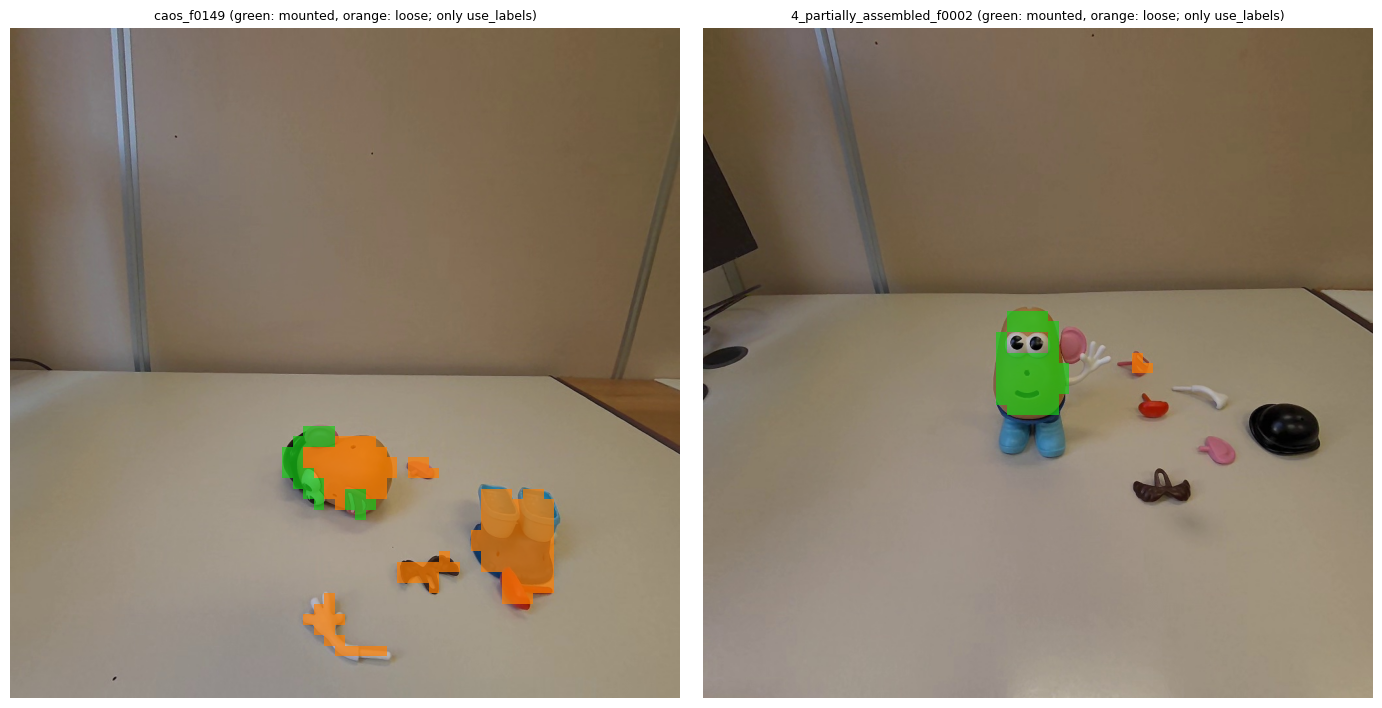

In [13]:
# 4.1 Aspect of every labelled patch: 0 = loose, 1 = mounted (background and hand: a single aspect)
LOOSE, MOUNTED = 0, 1
HAND_ID = CLASS_NAMES.index(HAND_LABEL)


def mounted_pixels(json_path):
    """Pixel mask of the polygons marked as mounted (group_id 1) in a labelme file."""
    with open(json_path) as f:
        annotation = json.load(f)
    mask = np.zeros((annotation["imageHeight"], annotation["imageWidth"]), dtype=np.uint8)
    for shape in annotation["shapes"]:
        if shape.get("group_id") == 1:
            cv2.fillPoly(mask, [np.round(np.array(shape["points"])).astype(np.int32)], 1)
    return mask.astype(bool)


def patch_fraction(mask, patch):
    """Fraction of each patch covered by a pixel mask."""
    h, w = mask.shape
    return mask[:h // patch * patch, :w // patch * patch].reshape(h // patch, patch, w // patch, patch).mean(axis=(1, 3))


for ref in REFERENCE_FRAMES:
    aspect = FRAME_ASPECT[ref["frame"]]
    groups = np.full(ref["patch_labels"].shape, LOOSE)
    if aspect == "mounted":
        groups[:] = MOUNTED
    elif aspect == "mixed":
        groups[patch_fraction(mounted_pixels(ref["json_path"]), PATCH_SIZE) >= MIN_LABEL_COVERAGE] = MOUNTED
    groups[np.isin(ref["patch_labels"], [BACKGROUND_ID, HAND_ID])] = LOOSE     # single aspect
    ref["patch_groups"] = groups

# Patches per class and aspect over the 10 reference frames
counts = {(name, aspect): sum(int(((ref["patch_labels"] == i) & (ref["patch_groups"] == g)).sum())
                              for ref in REFERENCE_FRAMES)
          for i, name in enumerate(CLASS_NAMES) for g, aspect in [(LOOSE, "loose"), (MOUNTED, "mounted")]}
display(pd.Series(counts).unstack().loc[CLASS_NAMES])

# Visual check of the two mixed frames: mounted patches green, loose patches orange
fig, axes = plt.subplots(1, 2, figsize=(14, 7))
for ax, name in zip(axes, [f for f, a in FRAME_ASPECT.items() if a == "mixed"]):
    ref = next(r for r in REFERENCE_FRAMES if r["frame"] == name)
    image = Image.open(ref["image_path"]).convert("RGB")
    is_piece = ~np.isin(ref["patch_labels"], [BACKGROUND_ID, HAND_ID, IGNORE_ID])
    overlay = np.zeros((*ref["patch_labels"].shape, 4))
    overlay[is_piece & (ref["patch_groups"] == MOUNTED)] = (0.1, 0.8, 0.1, 0.7)
    overlay[is_piece & (ref["patch_groups"] == LOOSE)] = (1.0, 0.5, 0.0, 0.7)
    ax.imshow(image)
    ax.imshow(overlay, extent=(0, image.width, image.height, 0), interpolation="nearest")
    ax.set_title(f"{name} (green: mounted, orange: loose; only use_labels)", fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

Observation 4.1: In the two mixed frames the aspects match the declared states. In caos_f0149 the lying body and the loose pieces are loose, while the mouth, the eyes, the hat and one ear, mounted on the body, are mounted. In 4_partially_assembled_f0002 the body on the base is mounted and the loose mouth is loose.

Over the 10 reference frames, body has 206 loose and 96 mounted patches, base 164 and 37. Several groups rest on few patches: arm_2 has 7 loose and 8 mounted, eyes 10 loose, nose 11 mounted. Splitting a class by aspect gives each prototype fewer examples, so these prototypes may be fragile.

In [14]:
# 4.2 The variants: (prototype matrix, class of each row)
prototypes_10, counts_10 = build_prototypes(REFERENCE_FRAMES)
v1_matrix, v1_owners, v1_groups, v1_counts = group_prototypes(REFERENCE_FRAMES)
v2_matrix, v2_owners = patch_prototypes(REFERENCE_FRAMES)

VARIANTS = {
    "V0 (8 frames)": (matrix_v0, owners_v0),                                    # descriptive comparison only
    "V0": (stack_prototypes(prototypes_10), np.arange(len(CLASS_NAMES))),
    "V1": (v1_matrix, v1_owners),
    "V2": (v2_matrix, v2_owners),
}
display(pd.DataFrame({name: {"prototypes": len(m)} for name, (m, o) in VARIANTS.items()}).T)

# V1: one prototype per class and aspect, with the number of patches behind each
display(pd.DataFrame({"class": [CLASS_NAMES[c] for c in v1_owners],
                      "aspect": ["mounted" if g == MOUNTED else "loose" for g in v1_groups],
                      "patches": v1_counts}))

,prototypes
V0 (8 frames),12
V0,12
V1,22
V2,39125


,class,aspect,patches
0,background,loose,37864
1,body,loose,206
2,body,mounted,96
3,base,loose,164
4,base,mounted,37
5,hat,loose,19
6,hat,mounted,33
7,eyes,loose,10
8,eyes,mounted,22
9,ear,loose,22


Observation 4.2: V0 has 12 prototypes, one per class, on both support sets. V1 has 22: two aspects for each of the 10 pieces, one prototype for background and one for hand. V2 has 39,125, one per labelled patch, of which 37,864 are background.

------------------------------------------------------------------------------------------------------------------------------------------

References Section 4:

Everingham et al. 2010, PASCAL VOC, Sect. 3.3: viewpoint annotated as an attribute of each object, to support methods that treat viewpoints separately 4.1.

Pipeline, Section 5: a patch takes a label if it covers at least half of the patch 4.1.

Snell et al. 2017, Sect. 2.2; Mensink et al. 2013, Sect. 1 and Sect. 3.3 4.2.

------------------------------------------------------------------------------------------------------------------------------------------

## Section 5 - Comparison of the variants

This section classifies the validation frames with every variant and compares their mIoU, as in the support-set study: over 10 pieces and with the arms merged, on the main metric and with the boundary ring ignored, at background margin 0 and 0.03. Each variant is compared with V0 on the 10 frames through the paired bootstrap interval of the difference, on the same 1000 resamples (Koehn 2004, Sect. 6). V0 on the current 8 frames describes the effect of the two frames added by the coverage rule. The decision rule of Section 1 is applied in Section 8.

In [15]:
# 5.1 Class similarities of every validation frame for every variant, computed once and then labelled
# for each background margin (same result as calling predict for each margin, without repeating the slow step)
SIMILARITIES = {name: [class_similarities(val["features"], prototypes, owners, chunk=PROTOTYPE_CHUNK)
                       for val in VALIDATION_FRAMES]
                for name, (prototypes, owners) in VARIANTS.items()}


def variant_confusions(name, margin, gt_key="gt_labels"):
    """Per-frame confusion matrices of one variant at one background margin."""
    return [confusion_matrix(val[gt_key], assign_labels(similarities, margin))
            for val, similarities in zip(VALIDATION_FRAMES, SIMILARITIES[name])]


CONF = {(name, gt_key, margin): variant_confusions(name, margin, gt_key)
        for name in VARIANTS for gt_key in ["gt_labels", "gt_tolerant"] for margin in EVAL_MARGINS}

# Check: V0 on the 8 current frames gives the confusion matrices of Section 3.4
print("V0 (8 frames) unchanged:", all(np.array_equal(a, b) for a, b in
                                      zip(CONF[("V0 (8 frames)", "gt_labels", CONFIDENCE_MARGIN)], conf_v0["gt_labels"])))

V0 (8 frames) unchanged: True


Observation 5.1: V0 on the current 8 frames gives the same confusion matrices as in Section 3.4, so the variants are evaluated with the same code as the current method.

In [16]:
# 5.2 mIoU of every variant and paired difference with V0 (10 frames)
rows = []
for gt_key in ["gt_labels", "gt_tolerant"]:
    for margin in EVAL_MARGINS:
        for merge in [False, True]:
            reference = CONF[("V0", gt_key, margin)]
            reference_boot = bootstrap_miou(reference, EXCLUDED, BOOTSTRAP_INDICES, merge)
            for name in VARIANTS:
                c = CONF[(name, gt_key, margin)]
                row = {"metric": gt_key, "background margin": margin,
                       "classes": "arms merged" if merge else "10 pieces", "variant": name,
                       "mIoU": frame_miou(c, EXCLUDED, merge=merge)}
                if name != "V0":
                    low, high = percentile_interval(bootstrap_miou(c, EXCLUDED, BOOTSTRAP_INDICES, merge) - reference_boot)
                    row.update({"delta vs V0": row["mIoU"] - frame_miou(reference, EXCLUDED, merge=merge),
                                "delta low": low, "delta high": high})
                rows.append(row)
display(pd.DataFrame(rows).round(3))

,metric,background margin,classes,variant,mIoU,delta vs V0,delta low,delta high
0,gt_labels,0.00,10 pieces,V0 (8 frames),0.612,-0.015,-0.026,-0.003
1,gt_labels,0.00,10 pieces,V0,0.626,NaN,NaN,NaN
2,gt_labels,0.00,10 pieces,V1,0.579,-0.047,-0.087,0.002
3,gt_labels,0.00,10 pieces,V2,0.823,0.197,0.137,0.251
4,gt_labels,0.00,arms merged,V0 (8 frames),0.654,-0.016,-0.029,-0.003
5,gt_labels,0.00,arms merged,V0,0.670,NaN,NaN,NaN
6,gt_labels,0.00,arms merged,V1,0.594,-0.076,-0.104,-0.039
7,gt_labels,0.00,arms merged,V2,0.864,0.194,0.148,0.231
8,gt_labels,0.03,10 pieces,V0 (8 frames),0.658,-0.015,-0.027,-0.003
9,gt_labels,0.03,10 pieces,V0,0.673,NaN,NaN,NaN


Observation 5.2: V2 is better than V0 in all eight settings, and every paired interval lies above zero. With the arms merged on the main metric at background margin 0.03, the mIoU goes from 0.725 to 0.861, a difference of +0.135 with the interval [0.093, 0.172]. With the boundary ring ignored the gain is smaller, +0.037 with the interval [0.006, 0.062]. A large part of the gain of V2 is therefore at the borders of the pieces, but recognition away from the borders also improves.

V1 is worse than V0 on the main metric: with the arms merged at 0.03, 0.662 against 0.725, a difference of −0.064 with the interval [−0.091, −0.033]. With the boundary ring ignored it is about equal to V0, with intervals that contain zero.

The two frames added by the coverage rule improve V0: with the arms merged at 0.03, 0.709 on the current 8 frames against 0.725 on 10 frames, a difference of +0.017 with the interval [0.003, 0.029] in favour of the 10 frames. This contradicts in part the hypothesis of Section 1 that they would change little.

Mensink et al. (2013) found the nearest class mean better than the nearest neighbour; here the opposite holds. Hypothesis: with few and very different examples per class, a mean blends them, while the nearest neighbour keeps them apart.

In [17]:
# 5.3 Per-class IoU, arms merged, main metric, background margin 0.03 (the setting of the decision rule)
display(pd.DataFrame({name: frame_iou(CONF[(name, "gt_labels", CONFIDENCE_MARGIN)], EXCLUDED, merge=True)
                      for name in VARIANTS}, index=MERGED_NAMES).round(3))

,V0 (8 frames),V0,V1,V2
background,0.991,0.991,0.988,0.999
body,0.764,0.768,0.780,0.942
base,0.778,0.785,0.793,0.945
hat,0.919,0.919,0.872,0.993
eyes,0.636,0.636,0.636,0.831
ear,0.697,0.719,0.611,0.919
nose,0.705,0.729,0.566,0.737
moustache,0.803,0.803,0.607,0.828
mouth,0.426,0.519,0.500,0.651
arm,0.651,0.651,0.589,0.899


Observation 5.3: With V2 every class improves over V0 (arms merged, main metric, background margin 0.03): body from 0.768 to 0.942, base from 0.785 to 0.945, hat from 0.919 to 0.993, arm from 0.651 to 0.899, ear from 0.719 to 0.919, mouth from 0.519 to 0.651. The face pieces, which the hypothesis of Section 1 indicated as at risk, also improve: nose from 0.729 to 0.737, moustache from 0.803 to 0.828, eyes from 0.636 to 0.831.

V1 loses most on ear (0.611), nose (0.566) and moustache (0.607), and on hat (0.872). Several V1 prototypes rest on few patches (Observation 4.1); this is a possible reason, not measured here.

The two added frames change V0 mainly on mouth, from 0.426 to 0.519, and slightly on ear and nose.

V2 classifies by the most similar reference patch. Reference and validation frames come from different recordings, but with the same table, light and period, so part of the gain may come from this similarity. Whether V2 generalizes to another setting is not measured here.

------------------------------------------------------------------------------------------------------------------------------------------

References Section 5: Koehn 2004, Sect. 6: paired bootstrap resampling, two systems compared on the same resampled test sets 5.2.

------------------------------------------------------------------------------------------------------------------------------------------

## Section 6 - Targeted measures

The mIoU summarizes all classes. This section looks at the three known limits directly, from the same confusion matrices, at background margin 0.03 on the main metric. The empty mouth slot: patches annotated as body and predicted as mouth, in the validation frames where the mouth is not mounted (assembly_2_f0003 and f0017, the two frames of 1_disassembled_controlled_caos). The arms: among the arm patches predicted as an arm, the share given the right arm, separately for loose arms and for the mounted arms of assembly_2_f0068. The loose mouth: its IoU in the two frames of 1_disassembled_controlled_caos, and in the side view (f0016) alone. These measures do not enter the decision rule (Section 1).

In [18]:
# 6.1 Targeted measures, from the confusion matrices (main metric, background margin 0.03)
INDEX = {val["frame"]: i for i, val in enumerate(VALIDATION_FRAMES)}
NO_MOUTH_FRAMES = ["assembly_2_f0003", "assembly_2_f0017",
                   "1_disassembled_controlled_caos_f0001", "1_disassembled_controlled_caos_f0016"]
MOUNTED_ARM_FRAMES = ["assembly_2_f0068"]
LOOSE_ARM_FRAMES = [f for f in INDEX if f not in MOUNTED_ARM_FRAMES]
LOOSE_MOUTH_FRAMES = ["1_disassembled_controlled_caos_f0001", "1_disassembled_controlled_caos_f0016"]
BODY, MOUTH = CLASS_NAMES.index("body"), CLASS_NAMES.index("mouth")
ARMS = [CLASS_NAMES.index("arm_1"), CLASS_NAMES.index("arm_2")]


def right_arm_share(confusions, frames):
    """Among arm patches predicted as an arm, the share predicted as the right arm."""
    right = sum(confusions[INDEX[f]][a, a] for f in frames for a in ARMS)
    any_arm = sum(confusions[INDEX[f]][np.ix_(ARMS, ARMS)].sum() for f in frames)
    return right / any_arm if any_arm else np.nan


rows = {}
for name in VARIANTS:
    c = CONF[(name, "gt_labels", CONFIDENCE_MARGIN)]
    rows[name] = {
        "body patches predicted as mouth (mouth not mounted)": int(sum(c[INDEX[f]][BODY, MOUTH] for f in NO_MOUTH_FRAMES)),
        "right arm share, loose": right_arm_share(c, LOOSE_ARM_FRAMES),
        "right arm share, mounted (f0068)": right_arm_share(c, MOUNTED_ARM_FRAMES),
        "mouth IoU, both caos frames": frame_iou(c, EXCLUDED, frames=[INDEX[f] for f in LOOSE_MOUTH_FRAMES])[MOUTH],
        "mouth IoU, side view (caos f0016)": frame_iou(c, EXCLUDED,
                                                       frames=[INDEX["1_disassembled_controlled_caos_f0016"]])[MOUTH],
    }
display(pd.DataFrame(rows).T.round(3))

,body patches predicted as mouth (mouth not mounted),"right arm share, loose","right arm share, mounted (f0068)","mouth IoU, both caos frames","mouth IoU, side view (caos f0016)"
V0 (8 frames),6.0,0.724,0.833,0.455,0.200
V0,5.0,0.724,0.833,0.583,0.333
V1,5.0,0.862,0.833,0.529,0.444
V2,0.0,0.844,1.000,0.727,0.667


Observation 6.1: In the four validation frames where the mouth is not mounted, 5 body patches are predicted as mouth with V0 (6 with V0 on the current 8 frames), 5 with V1 and none with V2. This confirms the hypothesis of Section 1: in V2 the annotated slot patches are body prototypes of their own.

The mouth IoU in the side view (1_disassembled_controlled_caos_f0016) goes from 0.200 with V0 on 8 frames to 0.333 with V0 on 10 frames and 0.667 with V2. Over the two frames of 1_disassembled_controlled_caos it goes from 0.455 to 0.583 and 0.727. These IoU rest on very few patches, so one patch changes them considerably.

Among the arm patches predicted as an arm, the right arm is given to 0.724 of the loose arm patches with V0, 0.862 with V1 and 0.844 with V2. For the mounted arms of assembly_2_f0068 the share goes from 0.833 with V0 and V1 to 1.000 with V2, on a single frame and few patches.

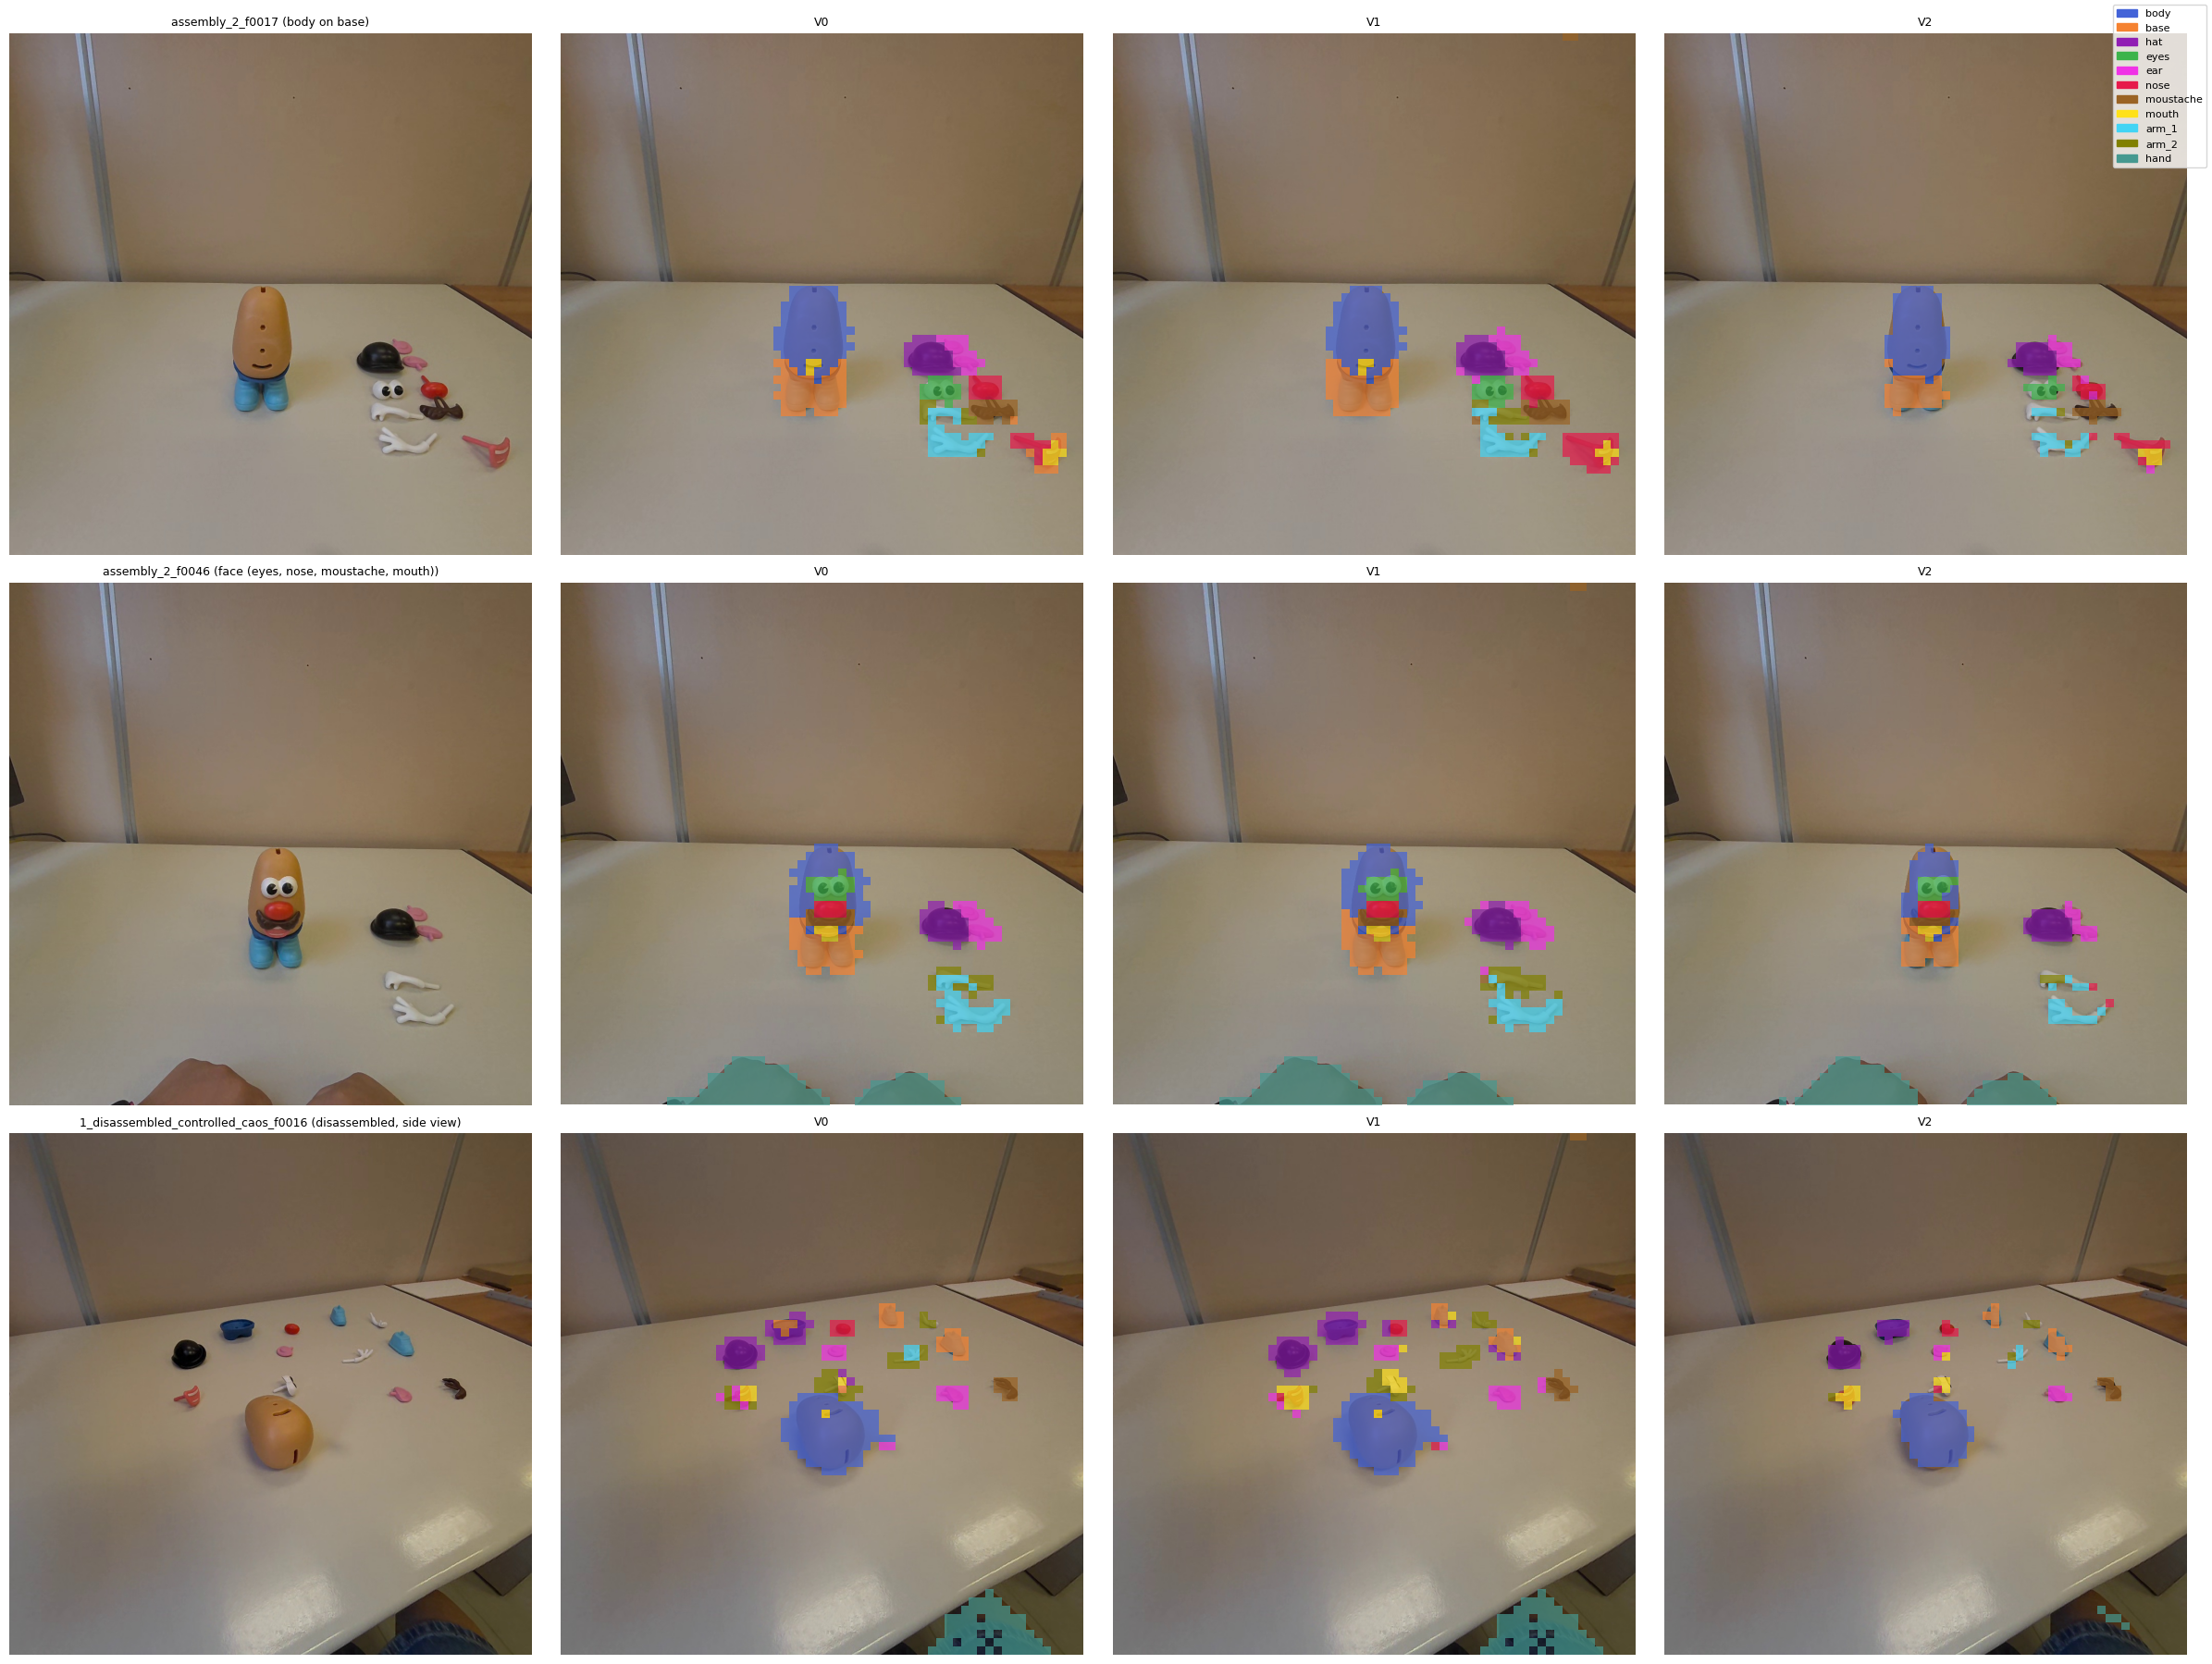

In [19]:
# 6.2 Predictions of V0, V1 and V2 (background margin 0.03) on the three frames of the known limits
FIGURE_FRAMES = ["assembly_2_f0017", "assembly_2_f0046", "1_disassembled_controlled_caos_f0016"]
SHOWN = ["V0", "V1", "V2"]

fig, axes = plt.subplots(len(FIGURE_FRAMES), len(SHOWN) + 1, figsize=(6 * (len(SHOWN) + 1), 6 * len(FIGURE_FRAMES)))
for row, name in zip(axes, FIGURE_FRAMES):
    i = INDEX[name]
    image = Image.open(frame_path(name)).convert("RGB")
    row[0].imshow(image)
    row[0].set_title(f"{name} ({VALIDATION_FRAMES[i]['stage']})", fontsize=9)
    for ax, variant in zip(row[1:], SHOWN):
        pred = assign_labels(SIMILARITIES[variant][i], CONFIDENCE_MARGIN)
        alpha = np.where(pred == BACKGROUND_ID, 0.0, 0.7)[..., None]
        ax.imshow(image)
        ax.imshow(np.concatenate([label_grid_to_rgb(pred), alpha], axis=-1),
                  extent=(0, image.width, image.height, 0), interpolation="nearest")
        ax.set_title(variant, fontsize=9)
    for ax in row:
        ax.axis("off")
fig.legend(handles=[mpatches.Patch(color=CLASS_COLORS[n], label=n) for n in CLASS_NAMES[1:]],
           loc="upper right", fontsize=8)
plt.tight_layout()
fig.savefig(OUTPUT_DIR / "predictions_V0_V1_V2.png", dpi=100, bbox_inches="tight")
plt.show()

Observation 6.2: In assembly_2_f0017 the empty mouth slot is predicted as mouth by V0 and V1 and as body by V2; the same holds for the lying body in 1_disassembled_controlled_caos_f0016. With V2 the predicted regions follow the pieces more closely, with fewer patches around them. Some errors remain with every variant: in assembly_2_f0017 the loose mouth, bottom right, is mostly predicted as nose. V2 also adds a few nose patches at the ends of the loose arms in assembly_2_f0046.

6.3 shows the three variants on the independent iPhone frame used in the pipeline as a qualitative check of a different camera (pipeline, Section 10.4). The frame is not annotated, so this check is only visual and does not enter any measure or the decision rule.

frame_1.jpeg: (1536, 2048) -> (768, 1024), patch grid (64, 48)


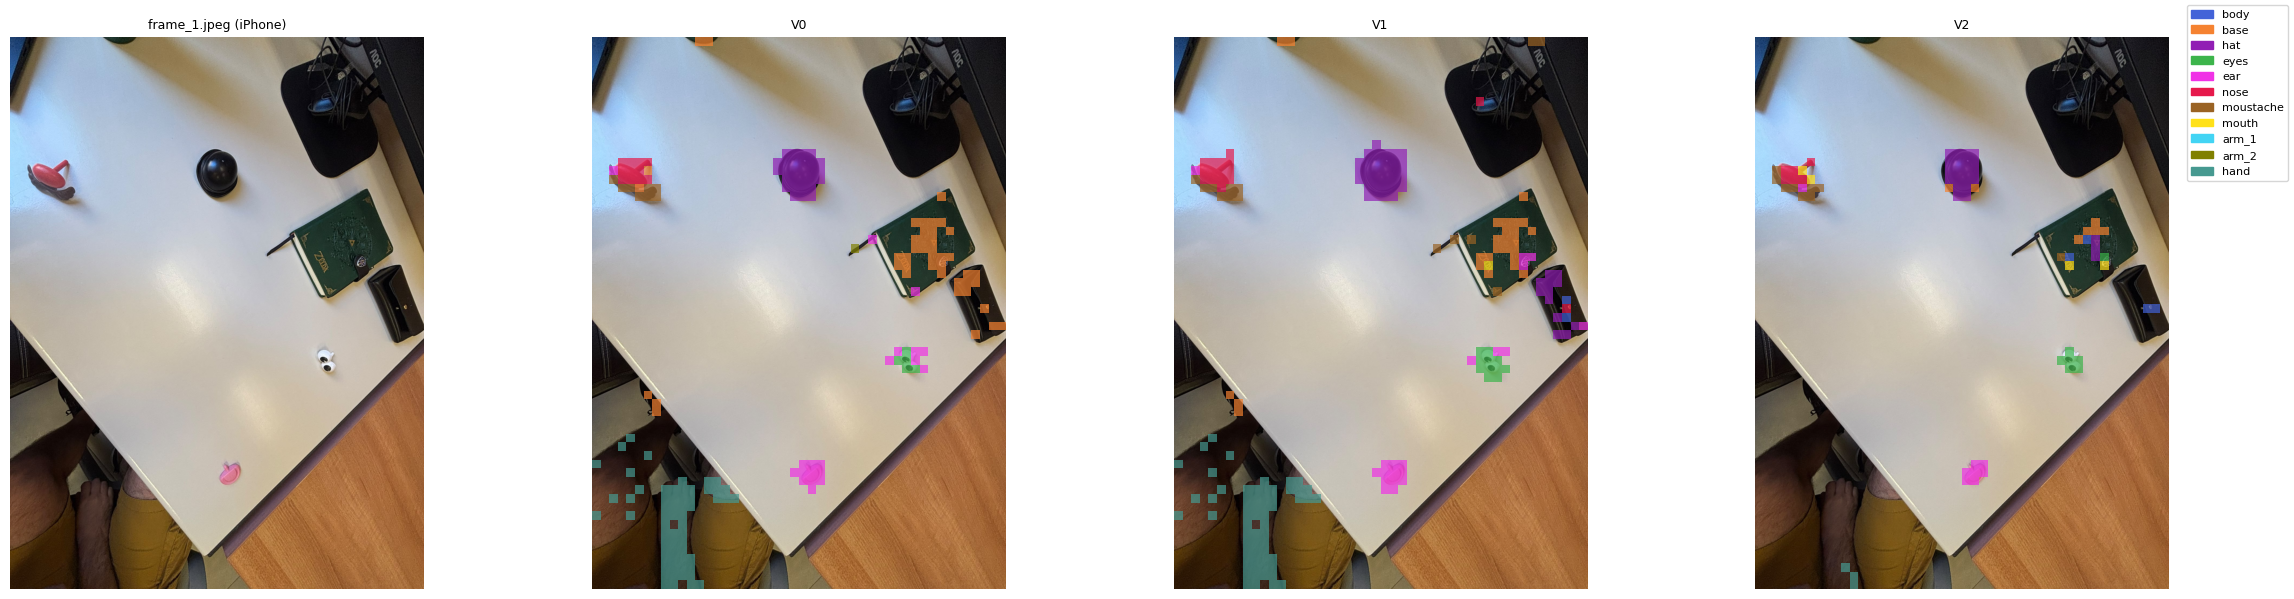

In [20]:
# 6.3 Qualitative check on a different camera: the independent iPhone frame (pipeline, Section 10.4).
# Not annotated: visual check only, outside the measures and the decision rule.
iphone_path = next((PROJECT_ROOT / "data").rglob("frame_1.jpeg"))
iphone = Image.open(iphone_path).convert("RGB")
iphone_features, iphone_size = extractor.extract(iphone, resolution=1024)   # longer side 1024, aspect ratio kept
print(f"{iphone_path.name}: {iphone.size} -> {iphone_size}, patch grid {iphone_features.shape[:2]}")

shown = iphone.resize(iphone_size)
fig, axes = plt.subplots(1, 4, figsize=(24, 6))
axes[0].imshow(shown)
axes[0].set_title(f"{iphone_path.name} (iPhone)", fontsize=9)
for ax, name in zip(axes[1:], ["V0", "V1", "V2"]):
    prototypes, owners = VARIANTS[name]
    pred = assign_labels(class_similarities(iphone_features, prototypes, owners, chunk=PROTOTYPE_CHUNK), CONFIDENCE_MARGIN)
    alpha = np.where(pred == BACKGROUND_ID, 0.0, 0.7)[..., None]
    ax.imshow(shown)
    ax.imshow(np.concatenate([label_grid_to_rgb(pred), alpha], axis=-1),
              extent=(0, shown.width, shown.height, 0), interpolation="nearest")
    ax.set_title(name, fontsize=9)
for ax in axes:
    ax.axis("off")
fig.legend(handles=[mpatches.Patch(color=CLASS_COLORS[n], label=n) for n in CLASS_NAMES[1:]],
           loc="upper right", fontsize=8)
plt.tight_layout()
fig.savefig(OUTPUT_DIR / "iphone_frame_V0_V1_V2.png", dpi=100, bbox_inches="tight")
plt.show()

Observation 6.3: The iPhone frame (1536x2048, resized to 768x1024, a 64x48 patch grid) shows a different camera and setting, with objects never seen in the reference frames: a green notebook, a black case, a mouse pad, a pen, the legs of a person. All three variants find the hat, the eyes and the ear. The loose mouth is mostly predicted as nose by V0 and V1, and partly as mouth by V2.

On the unseen objects the variants differ. V0 predicts the notebook and the case largely as base and the legs as hand; V1 does the same, with some hat, body and nose patches on the case. V2 predicts only a few scattered patches on these objects. With V2 the regions of the pieces are also somewhat smaller, for example on the hat and the mouth.

Hypothesis: with one background prototype, an unseen object can be closer to the mean of a piece than to the mean of the background; with 37,864 background prototypes, it is more likely to find a similar background patch. This is a single, unannotated frame, so the observation is only qualitative.

------------------------------------------------------------------------------------------------------------------------------------------

References Section 6: none. The measures are computed from the confusion matrices of Section 5.

------------------------------------------------------------------------------------------------------------------------------------------

## Section 7 - Time of classification

The variants change only the classification step: C-RADIO is the same. This section measures the time to classify one frame with each variant, from its features to its labels, with the protocol of the pipeline (Section 12): warm-up runs, then repeated runs, with the variants alternated run by run so that slow changes in the state of the laptop affect them alike. Classification runs in numpy on the CPU. For comparison, the C-RADIO forward pass takes about 360 ms per frame at 1024 on this laptop (resolution study, Section 5.4).

In [21]:
# 7.1 Time to classify one frame (features -> labels) with each variant, variants alternated run by run
timing_features = VALIDATION_FRAMES[0]["features"]
TIMED = ["V0", "V1", "V2"]


def classify_once(name):
    prototypes, owners = VARIANTS[name]
    return assign_labels(class_similarities(timing_features, prototypes, owners, chunk=PROTOTYPE_CHUNK),
                         CONFIDENCE_MARGIN)


for name in TIMED:                       # warm-up, not measured
    for _ in range(N_WARMUP):
        classify_once(name)

timings = {name: [] for name in TIMED}
for _ in range(N_RUNS):
    for name in TIMED:
        start = time.perf_counter()
        classify_once(name)
        timings[name].append((time.perf_counter() - start) * 1000)

table = pd.DataFrame({"median (ms)": {n: np.median(timings[n]) for n in TIMED},
                      "min (ms)": {n: np.min(timings[n]) for n in TIMED},
                      "max (ms)": {n: np.max(timings[n]) for n in TIMED}})
table["ratio to V0"] = table["median (ms)"] / table.loc["V0", "median (ms)"]
display(table.round(1))
print(f"CPU: {platform.processor()}")

,median (ms),min (ms),max (ms),ratio to V0
V0,23.1,18.1,39.6,1.0
V1,22.3,17.9,38.9,1.0
V2,4909.5,4241.8,5788.0,212.9


CPU: Intel64 Family 6 Model 170 Stepping 4, GenuineIntel


Observation 7.1: On the CPU, one frame is classified in about 20 ms with V0 and V1 and in about 5 s with V2, more than 200 times longer. V2 compares each of the 4096 patches with 39,125 prototypes, 37,864 of which are background. At this speed V2 could not be used in continuous perception: the 2444 frames of assembly_2 would take more than 3 hours of classification alone.

In [22]:
# 7.2 The same classification on the GPU: does it give the same labels as on the CPU?
VARIANTS_GPU = {}
for name, (prototypes, owners) in VARIANTS.items():
    if name in TIMED:
        sorted_prototypes, sorted_owners = sort_by_class(prototypes, owners)
        VARIANTS_GPU[name] = (torch.as_tensor(sorted_prototypes, device=DEVICE),
                              torch.as_tensor(sorted_owners, device=DEVICE))

rows = {}
for name in TIMED:
    max_diff, changed = 0.0, {margin: 0 for margin in EVAL_MARGINS}
    for val, cpu_similarities in zip(VALIDATION_FRAMES, SIMILARITIES[name]):
        gpu_similarities = class_similarities_gpu(val["features"], *VARIANTS_GPU[name])
        max_diff = max(max_diff, float(np.abs(gpu_similarities - cpu_similarities).max()))
        for margin in EVAL_MARGINS:
            changed[margin] += int((assign_labels(gpu_similarities, margin)
                                    != assign_labels(cpu_similarities, margin)).sum())
    rows[name] = {"max |GPU - CPU| similarity": max_diff,
                  **{f"patches with a different label, margin {m}": changed[m] for m in EVAL_MARGINS}}
display(pd.DataFrame(rows).T)
print(f"Patches compared per margin: {len(VALIDATION_FRAMES) * VALIDATION_FRAMES[0]['features'][..., 0].size}")

,max |GPU - CPU| similarity,"patches with a different label, margin 0.0","patches with a different label, margin 0.03"
V0,0.000002,0.0,0.0
V1,0.000001,0.0,0.0
V2,0.000002,0.0,0.0


Patches compared per margin: 32768


Observation 7.2: On the GPU the class similarities differ from those computed on the CPU by at most 0.000002, and no patch changes label: 0 of 32,768 validation patches, for every variant and both background margins. The GPU computation is therefore the same classification, and its timings apply to the variants as evaluated in Sections 5 and 6.

In [23]:
# 7.3 Time to classify one frame on the GPU (same protocol as 7.1, with GPU synchronization)
def classify_once_gpu(name):
    return assign_labels(class_similarities_gpu(timing_features, *VARIANTS_GPU[name]), CONFIDENCE_MARGIN)


for name in TIMED:                       # warm-up, not measured
    for _ in range(N_WARMUP):
        classify_once_gpu(name)

timings_gpu = {name: [] for name in TIMED}
for _ in range(N_RUNS):
    for name in TIMED:
        torch.cuda.synchronize()
        start = time.perf_counter()
        classify_once_gpu(name)
        torch.cuda.synchronize()
        timings_gpu[name].append((time.perf_counter() - start) * 1000)

table_gpu = pd.DataFrame({"median (ms)": {n: np.median(timings_gpu[n]) for n in TIMED},
                          "min (ms)": {n: np.min(timings_gpu[n]) for n in TIMED},
                          "max (ms)": {n: np.max(timings_gpu[n]) for n in TIMED},
                          "CPU median (ms)": {n: np.median(timings[n]) for n in TIMED}})
display(table_gpu.round(1))
print(f"GPU: {torch.cuda.get_device_name(0)}")

,median (ms),min (ms),max (ms),CPU median (ms)
V0,27.6,20.6,41.8,23.1
V1,25.6,19.9,41.2,22.3
V2,69.3,61.8,92.1,4909.5


GPU: NVIDIA GeForce RTX 4060 Laptop GPU


Observation 7.3: On the GPU, with the prototypes sorted by class, one frame is classified in about 70 to 80 ms with V2, against about 5 s on the CPU, and in about 25 to 35 ms with V0 and V1, slightly slower than on the CPU because with few prototypes moving the data costs more than the computation. With the C-RADIO forward pass at 1024, about 360 ms (resolution study, Section 5.4), perception with V2 takes about 430 to 440 ms per frame instead of about 390 with V0, about 10 to 15% more. Timings change between executions on this laptop and are given as ranges.

------------------------------------------------------------------------------------------------------------------------------------------

References Section 7: Pipeline, Section 12: latency protocol (warm-up, repeated runs); resolution study, Section 5.4: time of the C-RADIO forward pass at 1024.

------------------------------------------------------------------------------------------------------------------------------------------

## Section 8 - Decision and conclusions

This section applies the decision rule written in Section 1: a variant replaces V0 only if the paired 95% bootstrap interval of the mIoU difference, with the arms merged on the main metric at background margin 0.03, lies entirely above zero; if both variants pass, V1 is chosen unless V2 is better than V1 by the same criterion.

In [24]:
# 8.1 Decision rule of Section 1 (arms merged, main metric, background margin 0.03)
def paired(a, b):
    """Paired comparison of variant a against variant b: mIoU difference and its 95% bootstrap interval."""
    ca, cb = CONF[(a, "gt_labels", CONFIDENCE_MARGIN)], CONF[(b, "gt_labels", CONFIDENCE_MARGIN)]
    difference = (bootstrap_miou(ca, EXCLUDED, BOOTSTRAP_INDICES, merge=True)
                  - bootstrap_miou(cb, EXCLUDED, BOOTSTRAP_INDICES, merge=True))
    low, high = percentile_interval(difference)
    return {"delta": frame_miou(ca, EXCLUDED, merge=True) - frame_miou(cb, EXCLUDED, merge=True),
            "low": low, "high": high}


comparisons = {"V1 vs V0": paired("V1", "V0"), "V2 vs V0": paired("V2", "V0"), "V2 vs V1": paired("V2", "V1")}
display(pd.DataFrame(comparisons).T.round(3))

passes = {variant: comparisons[f"{variant} vs V0"]["low"] > 0 for variant in ["V1", "V2"]}
if passes["V1"] and passes["V2"]:
    chosen = "V2" if comparisons["V2 vs V1"]["low"] > 0 else "V1"
elif passes["V1"] or passes["V2"]:
    chosen = "V1" if passes["V1"] else "V2"
else:
    chosen = "V0"
print(f"Passes the rule: {passes} -> chosen: {chosen}")

,delta,low,high
V1 vs V0,-0.064,-0.091,-0.033
V2 vs V0,0.135,0.093,0.172
V2 vs V1,0.199,0.169,0.229


Passes the rule: {'V1': np.False_, 'V2': np.True_} -> chosen: V2


Observation 8.1: The rule selects V2. With the arms merged on the main metric at background margin 0.03, V2 is better than V0 by +0.135, with the paired interval [0.093, 0.172] entirely above zero, while V1 is worse than V0 by −0.064, with the interval [−0.091, −0.033]. V2 is also better than V1 by +0.199, with the interval [0.169, 0.229]; this comparison is not needed by the rule, since only V2 passes.

Result. V2, the nearest neighbour over every labelled reference patch, replaces the current method, on the support set of 10 frames. It is the only variant that passes the rule: with the arms merged on the main metric at background margin 0.03, its mIoU is 0.861 against 0.725 for V0, a difference of +0.135 with the interval [0.093, 0.172] (Section 5). V1 does not pass: its difference with V0 is −0.064, with the interval [−0.091, −0.033].

The known limits. With V2 no body patch is predicted as mouth where the mouth is not mounted, against 5 with V0 (Section 6). The mouth seen from the side goes from an IoU of 0.333 to 0.667, on very few patches. The arms are given the right identity more often, loose and mounted, but these measures rest on few patches and, for the mounted arms, on one frame.

Why. A mean loses the rare appearances of a class: the empty slot was one patch out of 251 body patches (Section 1), and the side view of the mouth is one patch. The nearest neighbour keeps every example (Mensink et al. 2013, Sect. 1). Mensink et al. found the nearest class mean better than the nearest neighbour in their setting; here the opposite holds. A likely reason, not tested here, is that each class has few examples with very different appearances. V1, which divides each class by aspect, loses on several face pieces, possibly because some of its prototypes rest on few patches (Observation 4.1).

Cost. V2 compares each patch with 39,125 prototypes. On the GPU this takes about 70 to 80 ms per frame, with exactly the same labels as on the CPU (Section 7), so perception takes about 430 to 440 ms per frame instead of about 390.

The support set. The two frames added by the coverage rule improve V0 by +0.017 (interval [0.003, 0.029]), mostly on the mouth. They are adopted by rule, not by this result.

Limitations. Validation has 8 frames from two recordings, and the two added frames were motivated by errors seen on validation, so the results are optimistic (Cawley and Talbot 2010, Sect. 4.4 and 5). The nearest neighbour relies on the similarity between reference and validation frames, recorded with the same table, light and period: whether V2 holds in another setting is not measured. Some errors remain: the loose mouth of assembly_2_f0017 is still mostly predicted as nose, and V2 adds a few nose patches at the ends of the loose arms in assembly_2_f0046. The background margin of 0.03 was set for V0; with V2 the similarity of a class is the highest over many prototypes, so its scale may differ, and the margin should be studied for V2. The cost of V2 grows with the number of reference patches.

Next steps. Update the pipeline to V2 on the 10 reference frames, with a regression check. Study the background margin for V2. Run continuous perception formally with V2. Record a robustness set in a different setting, reported separately. Then Phase 2, and the final evaluation on the test sequence (assembly_1), once.

Addendum, after the study: continuous perception on assembly_2. As an exploratory check, outside the decision rule, V0 and V2 were run on every frame of assembly_2 and compared against an event log annotated on the raw video (configs/assembly_2_events.json). V2 removes the mouth predicted on the empty slot (in every frame with V0, in none with V2), gives the right identity to both mounted arms, sees the loose mouth on the table more often (72% of the frames before its pick, against 43%) and predicts fewer pieces on unseen objects at the end of the video. It also predicts smaller regions, sees the loose arm_2 on the table much less often (10% of the frames before its pick, against 99%) and the hat less often (55% against 77%), and the small pieces flicker more when the scene is still. A possible reason, not measured, is the background margin of 0.03, set for V0: with 37,864 background prototypes, a piece may exceed the background by the margin less often. For this reason the pipeline is not updated yet, and the background margin is studied next, for V0 and V2.

------------------------------------------------------------------------------------------------------------------------------------------

References Section 8: Mensink et al. 2013, Sect. 1; Cawley and Talbot 2010, Sect. 4.4 and 5.

------------------------------------------------------------------------------------------------------------------------------------------